# Image Classification: Real or AI-Generated Photo

**Machine Learning 2 — Projekt**

Ziel: Ein **selbst gebautes CNN** (kein Transfer Learning) unterscheidet echte Fotografien von KI-generierten,
fotorealistischen Bildern. Wir bauen das Notebook im Stil der Assignments auf (v.a. *Assignment 2 — First CNN PyTorch*).

**Gliederung**

| Teil | Inhalt |
|:---|:---|
| A | Setup, Daten laden, Analyse, Dataset & DataLoader |
| B | Eigenes CNN-Modell + Dimensions-/Parametertabelle + Initialisierung |
| C | Training (Loss, Optimizer, LR-Schedule, Trainingsschleife) |
| D | Evaluation (Accuracy, Konfusionsmatrix, Fehleranalyse) |
| E | Kaggle-Submission |

**Datensatz (bereits geprüft):**
- 945 Trainingsbilder, nahezu balanciert (467 / 478)
- **Label 0 = KI-generiert, Label 1 = echtes Foto** (laut Kaggle-Beschreibung)
- 402 Testbilder
- **Motiv: ausschliesslich Blumen** - das ist fuer die Wahl der Augmentation entscheidend (s. A.7)
- Bilder quadratisch, aber sehr unterschiedlich groß (1024–4000 px), gemischt RGB/RGBA und JPEG/PNG
- Ordnerstruktur ist **verschachtelt**: `train/train/…` und `test/test/…`

> ⚠️ **Der Datensatz ist klein (945 Bilder).** Das Hauptrisiko ist Overfitting. Deshalb setzen wir konsequent auf
> Data Augmentation, Batch Normalization, Dropout und Global Average Pooling statt eines großen FC-Kopfes.

---
# Teil A — Setup und Daten

## A.1 Imports und Reproduzierbarkeit

Wie in Assignment 1 setzen wir feste Random Seeds (42), damit die Ergebnisse über mehrere Läufe stabil sind.

In [1]:
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset

import torchvision.transforms as transforms
from PIL import Image, ImageFile

# Manche JPEGs sind leicht beschaedigt -> PIL soll sie trotzdem laden
ImageFile.LOAD_TRUNCATED_IMAGES = True

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()

# Device: CUDA (NVIDIA) > MPS (Apple Silicon) > CPU
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("PyTorch:", torch.__version__)
print("Device :", device)

PyTorch: 2.11.0+cpu
Device : cpu


## A.2 Pfade und CSVs einlesen

Achtung auf die **verschachtelte Ordnerstruktur**: die Bilder liegen in `train/train/` bzw. `test/test/`.

In [2]:
# Basisordner des Datensatzes (liegt neben diesem Notebook)
DATA_DIR  = Path("Project_data")

TRAIN_DIR = DATA_DIR / "train" / "train"   # verschachtelt!
TEST_DIR  = DATA_DIR / "test"  / "test"    # verschachtelt!

# Label-Bedeutung laut Kaggle-Beschreibung
CLASS_NAMES = {0: "KI-generiert", 1: "Echtes Foto"}
CLASS_LIST  = [CLASS_NAMES[0], CLASS_NAMES[1]]   # Reihenfolge = Label-Index

train_df  = pd.read_csv(DATA_DIR / "train.csv")
test_df   = pd.read_csv(DATA_DIR / "test.csv")
sample_df = pd.read_csv(DATA_DIR / "sample_submission.csv")

print("train.csv :", train_df.shape, "| Spalten:", list(train_df.columns))
print("test.csv  :", test_df.shape,  "| Spalten:", list(test_df.columns))
print("submission:", sample_df.shape, "| Spalten:", list(sample_df.columns))
print()
display(train_df.head())

# Sanity-Check: existieren alle Dateien wirklich?
missing_train = [f for f in train_df["Image"] if not (TRAIN_DIR / f).exists()]
missing_test  = [f for f in test_df["Image"]  if not (TEST_DIR  / f).exists()]
print("Fehlende Trainingsbilder:", len(missing_train))
print("Fehlende Testbilder     :", len(missing_test))

train.csv : (945, 2) | Spalten: ['Image', 'Label']
test.csv  : (402, 1) | Spalten: ['Image']
submission: (402, 2) | Spalten: ['Image', 'Label']



,Image,Label
0,1.jpg,0
1,2.jpg,0
2,3.jpg,1
3,4.jpg,1
4,5.jpg,0


Fehlende Trainingsbilder: 0
Fehlende Testbilder     : 0


## A.3 Klassenverteilung

Ein unbalancierter Datensatz würde die Accuracy als Metrik verfälschen — deshalb prüfen wir das zuerst.

Label 0 (KI-generiert):  467  (49.4%)
Label 1 (Echtes Foto ):  478  (50.6%)


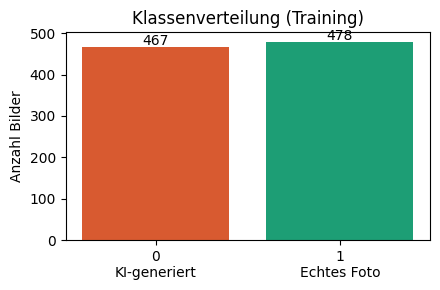

In [3]:
counts = train_df["Label"].value_counts().sort_index()
for lab, n in counts.items():
    print(f"Label {lab} ({CLASS_NAMES[lab]:12s}): {n:4d}  ({n / counts.sum():.1%})")

fig, ax = plt.subplots(figsize=(4.5, 3))
ax.bar([f"{lab}\n{CLASS_NAMES[lab]}" for lab in counts.index], counts.values,
       color=["#D85A30", "#1D9E75"])   # 0 = KI (orange), 1 = echt (gruen)
ax.set_ylabel("Anzahl Bilder"); ax.set_title("Klassenverteilung (Training)")
for i, v in enumerate(counts.values):
    ax.text(i, v + 5, str(v), ha="center")
plt.tight_layout(); plt.show()

**Ergebnis:** Der Datensatz ist mit 467 / 478 nahezu perfekt balanciert. Accuracy ist damit eine sinnvolle
Metrik, und die Baseline "immer die häufigste Klasse raten" liegt bei nur ~50,6 %.

## A.4 Bildeigenschaften analysieren

Bevor wir Transforms festlegen, schauen wir uns an, **wie** die Bilder überhaupt aussehen: Größe, Farbmodus, Dateiformat.
Das bestimmt direkt, welche Vorverarbeitung wir brauchen.

In [4]:
from collections import Counter

sizes, modes, formats = Counter(), Counter(), Counter()

for fname in train_df["Image"]:
    with Image.open(TRAIN_DIR / fname) as im:
        sizes[im.size] += 1
        modes[im.mode] += 1
        formats[im.format] += 1

print("Haeufigste Bildgroessen:", sizes.most_common(6))
print("Farbmodi               :", modes.most_common())
print("Dateiformate           :", formats.most_common())

all_w = [w for (w, h), n in sizes.items() for _ in range(n)]
print(f"\nBreite: min={min(all_w)}, max={max(all_w)}, median={int(np.median(all_w))}")

Haeufigste Bildgroessen: [((4000, 4000), 87), ((3264, 3264), 79), ((1080, 1080), 62), ((1024, 1024), 58), ((3467, 3467), 53), ((3456, 3456), 50)]
Farbmodi               : [('RGB', 887), ('RGBA', 58)]
Dateiformate           : [('JPEG', 887), ('PNG', 58)]

Breite: min=1024, max=5792, median=3264


**Zwei Konsequenzen für die Vorverarbeitung:**

1. **Gemischte Farbmodi (RGB und RGBA):** Wir müssen jedes Bild mit `.convert("RGB")` auf 3 Kanäle bringen,
   sonst bekommt das Netz mal 3, mal 4 Eingangskanäle → Fehler.
2. **Sehr unterschiedliche Größen (1024–4000 px):** Ein CNN braucht eine feste Eingabegröße. Wir skalieren
   auf `IMG_SIZE × IMG_SIZE`.

> 🔍 **Fachlicher Hinweis zum Runterskalieren:** KI-generierte Bilder verraten sich oft durch *hochfrequente*
> Artefakte (Rauschmuster, unsaubere Texturen im Detail). Starkes Downsampling glättet genau diese Signale weg.
> 128×128 ist ein pragmatischer Kompromiss für ein From-Scratch-CNN auf 945 Bildern. Wenn du später mehr
> Genauigkeit brauchst, ist ein `RandomCrop` in *nativer* Auflösung (statt Resize) das vielversprechendste
> Experiment — siehe Teil F.

## A.5 Beispielbilder beider Klassen

Laut Kaggle-Beschreibung gilt:

| Label | Bedeutung |
|:---:|:---|
| **0** | **KI-generiertes** Bild |
| **1** | **Echtes Foto** (von einem Fotografen aufgenommen) |

Wir sehen uns Beispiele beider Klassen an, um ein Gefühl dafür zu bekommen, woran das Netz die Klassen
überhaupt festmachen kann.

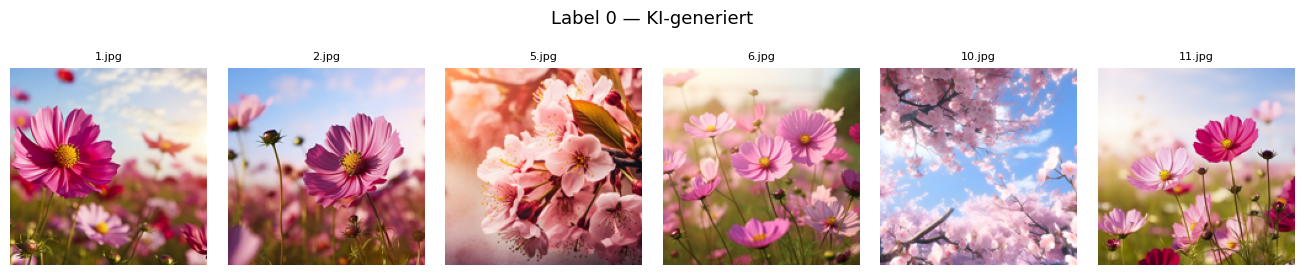

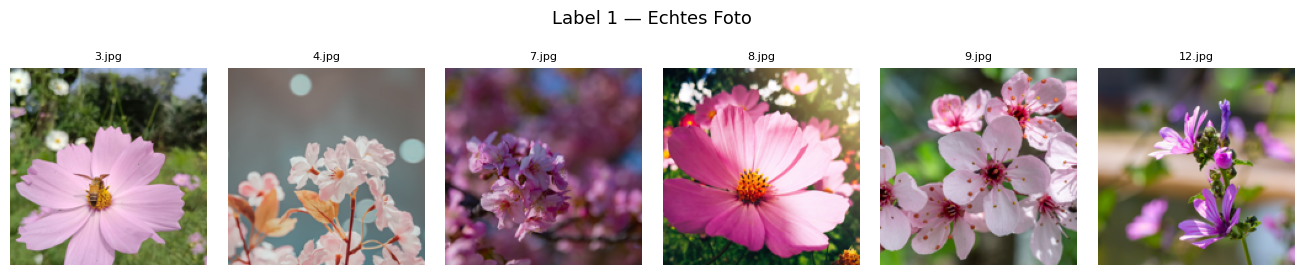

In [5]:
def show_examples(label, n=6):
    files = train_df.loc[train_df["Label"] == label, "Image"].head(n).tolist()
    fig, axes = plt.subplots(1, n, figsize=(2.2 * n, 2.6))
    for ax, f in zip(axes, files):
        with Image.open(TRAIN_DIR / f) as im:
            ax.imshow(im.convert("RGB").resize((160, 160)))
        ax.set_title(f, fontsize=8); ax.axis("off")
    fig.suptitle(f"Label {label} — {CLASS_NAMES[label]}", fontsize=13, y=1.04)
    plt.tight_layout(); plt.show()

show_examples(0)   # KI-generiert
show_examples(1)   # echte Fotos

## A.5b Bild-Cache anlegen (einmalig) — der wichtigste Performance-Schritt

Die Originalbilder sind 1024–4000 px groß. Jedes Dekodieren + Skalieren kostet **ca. 134 ms**. Da die
Transforms in *jeder* Epoche neu ausgeführt werden, bedeutet das:

| | ohne Cache | mit Cache |
|:---|---:|---:|
| pro Bild | ~134 ms | ~2 ms |
| pro Epoche (756 Bilder) | ~101 s | ~2 s |
| 40 Epochen | **> 60 min** | **< 2 min** |

Deshalb skalieren wir alle Bilder **einmal** auf 256 px vor und speichern sie in einen `cache/`-Ordner.
Danach zeigen `TRAIN_DIR` / `TEST_DIR` auf den Cache und alles Weitere bleibt unverändert.

Warum 256 und nicht direkt 128? So bleibt Spielraum für die Experimente aus Teil F (höhere Auflösung,
`RandomCrop`), ohne den Cache neu bauen zu müssen.

> 📌 **Ehrlicher Trade-off:** Der Cache speichert als JPEG (Qualität 98). Streng genommen ist das eine
> zweite verlustbehaftete Kompression, und KI-Artefakte sind hochfrequent. Praktisch dominiert aber das
> Herunterskalieren auf 256 px diesen Effekt bei Weitem. Wenn du später gezielt mit hochfrequenten
> Merkmalen arbeiten willst, setze `USE_CACHE = False` und nimm die längere Laufzeit in Kauf.

In [6]:
import time

USE_CACHE  = True      # dringend empfohlen
CACHE_SIZE = 256       # >= IMG_SIZE, laesst Spielraum fuer Experimente in Teil F

CACHE_DIR = Path("cache") / f"{CACHE_SIZE}px"


def build_cache(df, src_dir, dst_dir):
    '''Skaliert alle Bilder einmalig auf CACHE_SIZE und legt sie in dst_dir ab.'''
    dst_dir.mkdir(parents=True, exist_ok=True)
    made, skipped = 0, 0
    for fname in df["Image"]:
        out = dst_dir / fname
        if out.exists():          # schon gecacht -> ueberspringen (Zelle ist idempotent)
            skipped += 1
            continue
        with Image.open(src_dir / fname) as im:
            (im.convert("RGB")
               .resize((CACHE_SIZE, CACHE_SIZE), Image.BICUBIC)
               .save(out, "JPEG", quality=98))
        made += 1
    return made, skipped


if USE_CACHE:
    t0 = time.time()
    m_tr, s_tr = build_cache(train_df, TRAIN_DIR, CACHE_DIR / "train")
    m_te, s_te = build_cache(test_df,  TEST_DIR,  CACHE_DIR / "test")

    print(f"Cache in '{CACHE_DIR}':")
    print(f"  Training: {m_tr:4d} neu erstellt, {s_tr:4d} bereits vorhanden")
    print(f"  Test    : {m_te:4d} neu erstellt, {s_te:4d} bereits vorhanden")
    print(f"  Dauer   : {time.time() - t0:.1f}s  (einmalig)")

    # Ab hier alles aus dem Cache lesen. Dateinamen bleiben identisch,
    # daher muessen train_df/test_df NICHT angepasst werden.
    TRAIN_DIR = CACHE_DIR / "train"
    TEST_DIR  = CACHE_DIR / "test"
    print(f"\nTRAIN_DIR -> {TRAIN_DIR}")
    print(f"TEST_DIR  -> {TEST_DIR}")
else:
    print("Cache deaktiviert - es wird direkt von den Originalbildern gelesen (langsam).")

Cache in 'cache/256px':
  Training:    0 neu erstellt,  945 bereits vorhanden
  Test    :    0 neu erstellt,  402 bereits vorhanden
  Dauer   : 0.0s  (einmalig)

TRAIN_DIR -> cache/256px/train
TEST_DIR  -> cache/256px/test


👉 **Worauf du bei Blumen achten kannst.** Der Datensatz besteht ausschliesslich aus Blumenbildern, die
typischen "KI-Verräter" bei Menschen (Hände, Zähne, Ohren) helfen hier also nicht. Stattdessen:

| Hinweis auf **KI** (Label 0) | Hinweis auf **echtes Foto** (Label 1) |
|:---|:---|
| Blütenblätter zu symmetrisch / zu makellos | Kleine Schäden, Insektenfrass, welke Stellen |
| Blattadern laufen ins Nichts oder brechen ab | Durchgehende, botanisch plausible Aderung |
| Staubblätter/Pollen als unscharfer Brei | Feine, einzeln aufgelöste Staubgefässe |
| Bokeh unnatürlich gleichmässig, Übergänge "wattig" | Optisch korrekte Schärfentiefe, Sensorrauschen |
| Farben übersättigt, unnatürlich homogen | Natürliche Farbverläufe, Belichtungsfehler |

Genau diese **Texturunterschiede** soll unser CNN in den Faltungsschichten lernen — es geht weniger um die
Form der Blume als um die Beschaffenheit der Oberfläche.

## A.6 Normalisierungs-Statistiken berechnen

Wie in Assignment 3 (CIFAR-10) berechnen wir Mittelwert und Standardabweichung **auf den Trainingsdaten**,
statt blind ImageNet-Werte zu übernehmen. Wichtig — analog zum Lab des Gastdozenten: Die Statistiken werden
**nur auf dem Trainingsset** bestimmt, sonst leakt Information aus Validierung/Test ins Modell.

In [7]:
IMG_SIZE = 128   # Eingabegroesse des CNN

_stat_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])

_sum, _sum_sq, _n = torch.zeros(3), torch.zeros(3), 0
for fname in train_df["Image"]:
    with Image.open(TRAIN_DIR / fname) as im:
        x = _stat_tf(im.convert("RGB"))          # (3, H, W), Werte in [0,1]
    _sum    += x.mean(dim=(1, 2))
    _sum_sq += (x ** 2).mean(dim=(1, 2))
    _n      += 1

DATA_MEAN = (_sum / _n)
DATA_STD  = (_sum_sq / _n - DATA_MEAN ** 2).sqrt()

print("Mean:", DATA_MEAN.tolist())
print("Std :", DATA_STD.tolist())

Mean: [0.6024911403656006, 0.5128264427185059, 0.5154520869255066]
Std : [0.2585042715072632, 0.2389163374900818, 0.2940395474433899]


## A.7 Transforms: Augmentation gegen Overfitting

Bei nur 945 Bildern ist Augmentation der wirksamste Hebel. Wie in Assignment 2 gilt: **Augmentation nur auf
den Trainingsdaten**, Validierung und Test bekommen die saubere Variante.

**Das Motiv "Blume" erlaubt hier deutlich mehr als bei Fotos von Menschen oder Szenen** — eine Blume hat
keine kanonische Orientierung. Ein um 180° gedrehtes Blumenmakro ist ein völlig plausibles Foto, ein um 180°
gedrehtes Porträt nicht. Das verschafft uns zusätzliche, kostenlose Augmentation:

| Methode | Verwendet? | Begründung (Motiv Blume) |
|:---|:---|:---|
| Horizontal Flip | ✅ | Spiegelung ändert die Klasse nicht. |
| **Vertical Flip** | ✅ | Bei Blumen unbedenklich — anders als bei Szenen mit Horizont. |
| **Rotation bis 180°** | ✅ | Makro-/Draufsichtaufnahmen haben keine feste Ausrichtung. |
| **RandomResizedCrop** | ✅ | Zwingt das Netz auf *lokale Textur* statt auf die Gesamtkomposition — genau das Signal, das echte von KI-Blumen trennt. |
| ColorJitter (moderat) | ✅ | Robustheit gegen Belichtung. Nicht zu stark: Farbsättigung ist ein echtes Indiz für KI-Bilder. |
| RandomErasing | ✅ | Verhindert, dass sich das Netz auf eine einzelne Bildregion verlässt. |
| Graustufen | ❌ | Würde die Farbstatistik als Merkmal zerstören. |

> 📊 **Empirisch geprüft:** Diese blumenspezifische Augmentation wurde gegen die ursprüngliche, konservative
> Variante getestet — Ergebnisse in Abschnitt D.4.

In [8]:
# Blumenspezifische Augmentation: volle Rotationsfreiheit + Crop auf lokale Textur
train_transform = transforms.Compose([
    transforms.RandomRotation(180),                                   # Blumen: keine feste Ausrichtung
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.4, 0.9), ratio=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.03),
    transforms.ToTensor(),
    transforms.Normalize(DATA_MEAN, DATA_STD),
    transforms.RandomErasing(p=0.25),                                 # wirkt auf den Tensor
])

# Validierung & Test: KEINE Augmentation
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(DATA_MEAN, DATA_STD),
])

## A.8 Eigene Dataset-Klasse

Anders als in Assignment 2 (dort kam CIFAR-10 fertig aus `torchvision`) liegt unser Datensatz als
**CSV + Bildordner** vor. Wir schreiben deshalb eine eigene `Dataset`-Subklasse. Sie muss drei Methoden haben:
`__init__`, `__len__` und `__getitem__`.

In [9]:
class RealOrAIDataset(Dataset):
    '''Bilddatensatz aus CSV (Spalte "Image", optional "Label") + Bildordner.'''

    def __init__(self, df, img_dir, transform=None, has_labels=True):
        self.df        = df.reset_index(drop=True)
        self.img_dir   = Path(img_dir)
        self.transform = transform
        self.has_labels = has_labels

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        fname = row["Image"]

        # .convert("RGB") vereinheitlicht RGBA/Graustufen auf 3 Kanaele
        with Image.open(self.img_dir / fname) as im:
            image = im.convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        if self.has_labels:
            label = int(row["Label"])
            return image, label
        return image, fname     # beim Test brauchen wir den Dateinamen fuer die Submission

## A.9 Train/Validation-Split — und das Transform-Dilemma

Hier taucht **genau das Problem aus Assignment 2** wieder auf: Die Validierungsdaten sollen aus dem
Trainingsdatensatz stammen, aber **ohne** Augmentation verarbeitet werden.

**Lösung:** Wir bauen den Datensatz *zweimal* — einmal mit `train_transform`, einmal mit `eval_transform` —
und teilen mit **denselben Indizes**. Aus dem augmentierten Objekt nehmen wir die Trainings-Indizes, aus dem
sauberen Objekt die Validierungs-Indizes.

Zusätzlich splitten wir **stratifiziert**, damit die Klassenverteilung in beiden Teilen erhalten bleibt.

In [10]:
from sklearn.model_selection import train_test_split

VAL_FRACTION = 0.2

train_idx, val_idx = train_test_split(
    np.arange(len(train_df)),
    test_size=VAL_FRACTION,
    random_state=SEED,
    shuffle=True,
    stratify=train_df["Label"].values,   # Klassenverhaeltnis bleibt erhalten
)

# Zweimal derselbe Datensatz, aber mit unterschiedlichen Transforms
ds_augmented = RealOrAIDataset(train_df, TRAIN_DIR, transform=train_transform)
ds_clean     = RealOrAIDataset(train_df, TRAIN_DIR, transform=eval_transform)

train_ds = Subset(ds_augmented, train_idx)   # MIT Augmentation
val_ds   = Subset(ds_clean,     val_idx)     # OHNE Augmentation

print(f"Training  : {len(train_ds)} Bilder")
print(f"Validation: {len(val_ds)} Bilder")

# Kontrolle: Klassenverteilung nach dem Split
print("\nVerteilung Training  :", np.bincount(train_df['Label'].values[train_idx]))
print("Verteilung Validation:", np.bincount(train_df['Label'].values[val_idx]))

Training  : 756 Bilder
Validation: 189 Bilder

Verteilung Training  : [374 382]
Verteilung Validation: [93 96]


## A.10 DataLoader

> ⚠️ **`NUM_WORKERS = 0` auf macOS.** Jupyter startet DataLoader-Worker per `spawn`; die Kindprozesse
> müssen das Notebook-Modul neu importieren, was fehlschlägt — Symptom:
> `RuntimeError: DataLoader worker (pid(s) ...) exited unexpectedly`.
> Unter Linux (`fork`) funktionieren Worker problemlos, dort kannst du 2–4 setzen.

Den Geschwindigkeitsverlust durch `num_workers=0` fangen wir über den Bild-Cache aus A.5b wieder auf.

In [11]:
BATCH_SIZE  = 32
NUM_WORKERS = 0      # macOS + Jupyter: MUSS 0 sein (spawn-Worker crashen sonst)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, drop_last=False)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS)

# Ein Batch zur Kontrolle
images, labels = next(iter(train_loader))
print("Batch-Shape :", images.shape)      # erwartet: (32, 3, 128, 128)
print("Label-Shape :", labels.shape)
print("Wertebereich:", images.min().item().__round__(2), "bis", images.max().item().__round__(2))

Batch-Shape : torch.Size([32, 3, 128, 128])
Label-Shape : torch.Size([32])
Wertebereich: -2.33 bis 2.04


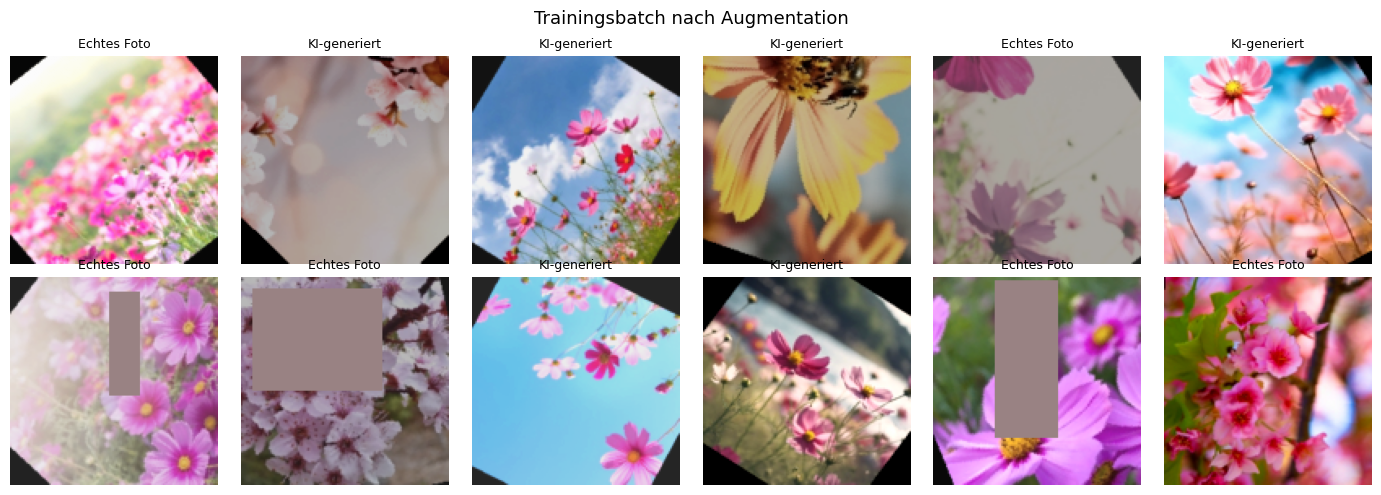

In [12]:
def denormalize(t):
    '''Macht die Normalisierung fuer die Anzeige rueckgaengig.'''
    return (t * DATA_STD[:, None, None] + DATA_MEAN[:, None, None]).clamp(0, 1)

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, img, lab in zip(axes.flat, images, labels):
    ax.imshow(denormalize(img).permute(1, 2, 0).numpy())
    ax.set_title(CLASS_NAMES[lab.item()], fontsize=9)
    ax.axis("off")
fig.suptitle("Trainingsbatch nach Augmentation", fontsize=13)
plt.tight_layout(); plt.show()

---
# Teil B — Das Modell

## B.1 Architektur

Wir bauen ein CNN als `nn.Module`-Subklasse, aufgebaut aus vier Blöcken nach dem Schema aus Assignment 2:

`Conv2d → BatchNorm → ReLU → Dropout2d → MaxPool`

Danach folgt **Global Average Pooling** statt eines großen Fully-Connected-Kopfes. Das ist die wichtigste
Design-Entscheidung gegen Overfitting: Ein `Flatten` nach dem letzten Block hätte 256·8·8 = 16.384 Eingänge
und damit über 32.000 Parameter allein in der letzten Schicht — bei 756 Trainingsbildern ein sicherer Weg ins
Auswendiglernen. Global Average Pooling reduziert auf 256 Werte und braucht nur 514 Parameter.

**Hinweis (vgl. Assignment 2):** Die letzte Schicht hat *keinen* Softmax, weil `nn.CrossEntropyLoss`
den (Log-)Softmax bereits intern anwendet.

In [13]:
class RealOrAICNN(nn.Module):
    def __init__(self, num_classes=2, dropout_conv=0.30, dropout_fc=0.5):
        super().__init__()

        def block(in_ch, out_ch):
            return nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),  # 'same' -> Groesse bleibt
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True),
                nn.Dropout2d(dropout_conv),
                nn.MaxPool2d(kernel_size=2, stride=2),               # halbiert H und W
            )

        self.features = nn.Sequential(
            block(3,   32),    # 128 -> 64
            block(32,  64),    #  64 -> 32
            block(64,  128),   #  32 -> 16
            block(128, 256),   #  16 -> 8
        )

        self.global_pool = nn.AdaptiveAvgPool2d(1)   # (256, 8, 8) -> (256, 1, 1)
        self.classifier  = nn.Sequential(
            nn.Flatten(),                # -> (256,)
            nn.Dropout(dropout_fc),
            nn.Linear(256, num_classes), # KEIN Softmax (steckt in CrossEntropyLoss)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.global_pool(x)
        return self.classifier(x)


set_seed()
model = RealOrAICNN().to(device)
print(model)

RealOrAICNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Dropout2d(p=0.3, inplace=False)
      (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Dropout2d(p=0.3, inplace=False)
      (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Dropout2d(p=0.3, inpla

## B.2 Dimensions- und Parametertabelle

Genau die Rechnung, die auch als Theoriefrage in Assignment 2 und in der Probeklausur vorkommt.
Eingabe: **3 × 128 × 128**.

Erinnerung an die Formeln:
- Conv-Output: `⌊(H − k + 2p)/s⌋ + 1`; hier k=3, p=1, s=1 → Größe bleibt gleich
- Conv-Parameter: `N · (k · k · C_in + 1)`
- BatchNorm: `2 · C` lernbare Parameter (γ und β)
- MaxPool / ReLU / Dropout / Flatten: **0** Parameter
- Linear: `(n_in + 1) · n_out`

| Layer | Output (C×H×W) | Weights | Biases | Summe |
|:---|:---|:---|:---|:---|
| Conv2d 1 | 32×128×128 | 3·3·3·32 = 864 | 32 | 896 |
| BatchNorm 1 | 32×128×128 | 32 | 32 | 64 |
| MaxPool 1 | 32×64×64 | 0 | 0 | 0 |
| Conv2d 2 | 64×64×64 | 32·3·3·64 = 18.432 | 64 | 18.496 |
| BatchNorm 2 | 64×64×64 | 64 | 64 | 128 |
| MaxPool 2 | 64×32×32 | 0 | 0 | 0 |
| Conv2d 3 | 128×32×32 | 64·3·3·128 = 73.728 | 128 | 73.856 |
| BatchNorm 3 | 128×32×32 | 128 | 128 | 256 |
| MaxPool 3 | 128×16×16 | 0 | 0 | 0 |
| Conv2d 4 | 256×16×16 | 128·3·3·256 = 294.912 | 256 | 295.168 |
| BatchNorm 4 | 256×16×16 | 256 | 256 | 512 |
| MaxPool 4 | 256×8×8 | 0 | 0 | 0 |
| GlobalAvgPool | 256×1×1 | 0 | 0 | 0 |
| Flatten | 256 | 0 | 0 | 0 |
| Linear | 2 | 256·2 = 512 | 2 | 514 |
| **Gesamt** | | | | **389.890** |

Die nächste Zelle prüft diese Handrechnung programmatisch nach.

In [14]:
# Gegenprobe: Parameterzahl und Shapes automatisch bestimmen
total = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainierbare Parameter (gezaehlt): {total:,}")
print(f"Handrechnung aus der Tabelle     : {389890:,}")
print("Stimmt ueberein:", total == 389890)

# Shapes Schicht fuer Schicht
print("\nShape nach jedem Block:")
x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(device)
with torch.no_grad():
    for i, blk in enumerate(model.features, start=1):
        x = blk(x)
        print(f"  nach Block {i}: {tuple(x.shape)}")
    x = model.global_pool(x); print(f"  nach GlobalAvgPool: {tuple(x.shape)}")
    x = model.classifier(x);  print(f"  Output (Logits)   : {tuple(x.shape)}")

Trainierbare Parameter (gezaehlt): 389,890
Handrechnung aus der Tabelle     : 389,890
Stimmt ueberein: True

Shape nach jedem Block:
  nach Block 1: (1, 32, 64, 64)
  nach Block 2: (1, 64, 32, 32)
  nach Block 3: (1, 128, 16, 16)
  nach Block 4: (1, 256, 8, 8)
  nach GlobalAvgPool: (1, 256, 1, 1)
  Output (Logits)   : (1, 2)


## B.3 Gewichts-Initialisierung

Da im Netz **ReLU**-Aktivierungen stecken, initialisieren wir die Conv- und Linear-Schichten mit
**He-/Kaiming-Initialisierung** (`Var(W) = 2 / n_in`) — genau die Theoriefrage aus Assignment 1 und 2.
Ziel: Die Varianz der Aktivierungen bleibt zu Trainingsbeginn über die Schichten hinweg stabil, sodass
weder verschwindende noch explodierende Gradienten auftreten.

In [15]:
def init_weights(m):
    if isinstance(m, nn.Conv2d):
        nn.init.kaiming_normal_(m.weight, mode="fan_in", nonlinearity="relu")
        if m.bias is not None:
            nn.init.zeros_(m.bias)
    elif isinstance(m, nn.Linear):
        nn.init.kaiming_normal_(m.weight, mode="fan_in", nonlinearity="relu")
        nn.init.zeros_(m.bias)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.ones_(m.weight)     # gamma
        nn.init.zeros_(m.bias)      # beta

set_seed()
model = RealOrAICNN().to(device)
model.apply(init_weights)
print("He-Initialisierung angewendet.")

He-Initialisierung angewendet.


---
# Teil C — Training

## C.1 Loss, Optimizer und Learning-Rate-Schedule

- **Loss:** `nn.CrossEntropyLoss` — enthält den Softmax bereits, deshalb gibt das Modell rohe Logits aus.
- **Optimizer:** `AdamW` (Adam mit korrektem Weight Decay) — adaptive Lernrate aus Kapitel 2.2.
- **Schedule:** `CosineAnnealingLR` senkt die Lernrate über das Training glatt ab (Kapitel 2.2,
  Learning-Rate-Schedules). Das stabilisiert die Endphase des Trainings.
- **Weight Decay** wirkt als zusätzliche L2-Regularisierung gegen Overfitting.

In [16]:
EPOCHS        = 20        # gemessen: ab Epoche ~7 liegt die Train-Accuracy bei 100 %, mehr bringt nichts
LEARNING_RATE = 1e-3
WEIGHT_DECAY  = 1e-3      # staerker als der Default 1e-4, gegen das beobachtete Overfitting

criterion = nn.CrossEntropyLoss(label_smoothing=0.05)   # daempft uebersteigerte Konfidenz
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

## C.2 Trainings- und Evaluationsfunktion

Aufbau der Trainingsschleife exakt wie in Assignment 2:
Modell in `train()`-Modus → Batch auf das Device → Forward Pass → Loss berechnen → `zero_grad()` →
`backward()` (Backpropagation) → `step()` (ein Schritt in Richtung des negativen Gradienten).

In [17]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()                      # aktiviert Dropout und BatchNorm-Updates
    running_loss, correct, total = 0.0, 0, 0

    for data, targets in loader:
        data, targets = data.to(device), targets.to(device)

        outputs = model(data)                  # Forward Pass
        loss    = criterion(outputs, targets)  # Loss

        optimizer.zero_grad()                  # alte Gradienten loeschen
        loss.backward()                        # Backpropagation
        optimizer.step()                       # Gewichtsupdate

        running_loss += loss.item() * data.size(0)
        correct      += (outputs.argmax(dim=1) == targets).sum().item()
        total        += targets.size(0)

    return running_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()                       # Dropout aus, BatchNorm nutzt laufende Statistiken
    running_loss, correct, total = 0.0, 0, 0

    for data, targets in loader:
        data, targets = data.to(device), targets.to(device)
        outputs = model(data)
        loss    = criterion(outputs, targets)

        running_loss += loss.item() * data.size(0)
        correct      += (outputs.argmax(dim=1) == targets).sum().item()
        total        += targets.size(0)

    return running_loss / total, correct / total

## C.3 Trainingsschleife

Wir merken uns das Modell mit der **besten Validierungs-Accuracy** (nicht das der letzten Epoche). Das ist
eine einfache Form von Early Stopping: Wenn das Netz später zu overfitten beginnt, haben wir den besten
Stand bereits gesichert.

In [18]:
import copy, time

history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "lr": []}

best_val_acc = 0.0
best_state   = copy.deepcopy(model.state_dict())
start        = time.time()

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    va_loss, va_acc = evaluate(model, val_loader, criterion, device)

    history["train_loss"].append(tr_loss); history["train_acc"].append(tr_acc)
    history["val_loss"].append(va_loss);   history["val_acc"].append(va_acc)
    history["lr"].append(optimizer.param_groups[0]["lr"])

    scheduler.step()

    flag = ""
    if va_acc > best_val_acc:
        best_val_acc = va_acc
        best_state   = copy.deepcopy(model.state_dict())
        flag = "  <-- neues bestes Modell"

    print(f"Epoch {epoch:2d}/{EPOCHS} | "
          f"train loss {tr_loss:.4f}, acc {tr_acc:.4f} | "
          f"val loss {va_loss:.4f}, acc {va_acc:.4f}{flag}")

print(f"\nFertig in {time.time() - start:.1f}s. Beste Validierungs-Accuracy: {best_val_acc:.4f}")

model.load_state_dict(best_state)          # bestes Modell wiederherstellen
torch.save(best_state, "best_model.pt")    # und auf Platte sichern

Epoch  1/20 | train loss 1.2324, acc 0.5132 | val loss 0.6628, acc 0.6720  <-- neues bestes Modell
Epoch  2/20 | train loss 1.1823, acc 0.4802 | val loss 0.6434, acc 0.6349
Epoch  3/20 | train loss 0.9950, acc 0.5370 | val loss 0.5988, acc 0.6825  <-- neues bestes Modell
Epoch  4/20 | train loss 0.9427, acc 0.5251 | val loss 0.5932, acc 0.7196  <-- neues bestes Modell
Epoch  5/20 | train loss 0.8414, acc 0.5582 | val loss 0.5852, acc 0.6667
Epoch  6/20 | train loss 0.8531, acc 0.5304 | val loss 0.5636, acc 0.7619  <-- neues bestes Modell
Epoch  7/20 | train loss 0.8273, acc 0.5450 | val loss 0.5662, acc 0.7937  <-- neues bestes Modell
Epoch  8/20 | train loss 0.7942, acc 0.5516 | val loss 0.5714, acc 0.7831
Epoch  9/20 | train loss 0.7607, acc 0.5648 | val loss 0.5682, acc 0.7354
Epoch 10/20 | train loss 0.7556, acc 0.5701 | val loss 0.5630, acc 0.7354
Epoch 11/20 | train loss 0.7754, acc 0.5860 | val loss 0.5598, acc 0.7884
Epoch 12/20 | train loss 0.8000, acc 0.5463 | val loss 0.5662

## C.4 Lernkurven

Die Lernkurven sind das wichtigste Diagnosewerkzeug. Achte auf die **Lücke zwischen Trainings- und
Validierungskurve** — genau die Frage aus der Probeklausur (Aufgabe 2a):

- Train-Accuracy steigt weiter, Val-Accuracy stagniert → **Overfitting** → mehr Augmentation/Dropout, kleineres Modell
- Beide bleiben niedrig → **Underfitting** → größeres Modell, längeres Training, höhere Lernrate

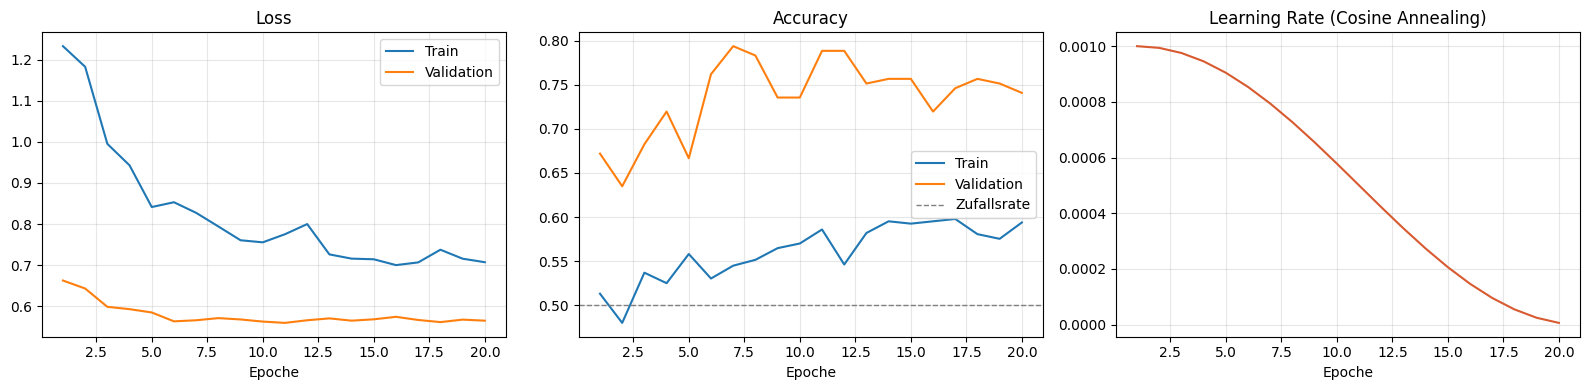

Gap Train- vs. Validierungs-Accuracy in der letzten Epoche: -0.147


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ep = range(1, len(history["train_loss"]) + 1)

axes[0].plot(ep, history["train_loss"], label="Train")
axes[0].plot(ep, history["val_loss"],   label="Validation")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoche"); axes[0].legend(); axes[0].grid(alpha=.3)

axes[1].plot(ep, history["train_acc"], label="Train")
axes[1].plot(ep, history["val_acc"],   label="Validation")
axes[1].axhline(0.5, ls="--", c="grey", lw=1, label="Zufallsrate")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoche"); axes[1].legend(); axes[1].grid(alpha=.3)

axes[2].plot(ep, history["lr"], c="#D85A30")
axes[2].set_title("Learning Rate (Cosine Annealing)"); axes[2].set_xlabel("Epoche"); axes[2].grid(alpha=.3)

plt.tight_layout(); plt.show()

gap = history["train_acc"][-1] - history["val_acc"][-1]
print(f"Gap Train- vs. Validierungs-Accuracy in der letzten Epoche: {gap:.3f}")

---
# Teil D — Evaluation

## D.1 Konfusionsmatrix

Die Konfusionsmatrix war die Antwort auf eine Theoriefrage in Assignment 1: Sie zeigt nicht nur *wie viel*,
sondern **welche** Klasse das Modell verwechselt.

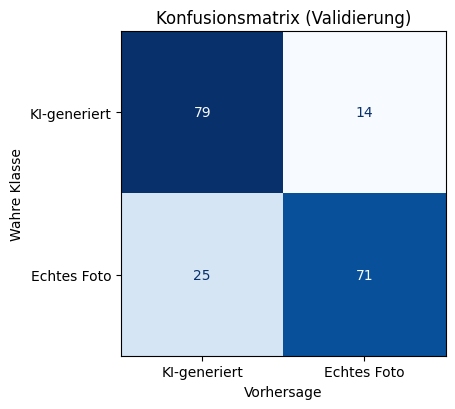

              precision    recall  f1-score   support

KI-generiert     0.7596    0.8495    0.8020        93
 Echtes Foto     0.8353    0.7396    0.7845        96

    accuracy                         0.7937       189
   macro avg     0.7975    0.7945    0.7933       189
weighted avg     0.7981    0.7937    0.7931       189

KI-Bild faelschlich als 'echt' eingestuft (False Positive): 14
Echtes Foto faelschlich als 'KI' eingestuft (False Negative): 25


In [20]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

@torch.no_grad()
def get_predictions(model, loader, device):
    model.eval()
    all_preds, all_targets, all_probs = [], [], []
    for data, targets in loader:
        data = data.to(device)
        logits = model(data)
        probs  = torch.softmax(logits, dim=1)     # hier explizit, fuer Wahrscheinlichkeiten
        all_preds.append(logits.argmax(dim=1).cpu())
        all_probs.append(probs.cpu())
        all_targets.append(targets)
    return (torch.cat(all_preds).numpy(),
            torch.cat(all_targets).numpy(),
            torch.cat(all_probs).numpy())

val_preds, val_targets, val_probs = get_predictions(model, val_loader, device)

cm = confusion_matrix(val_targets, val_preds)
fig, ax = plt.subplots(figsize=(5, 4.2))
ConfusionMatrixDisplay(cm, display_labels=CLASS_LIST).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Konfusionsmatrix (Validierung)")
ax.set_xlabel("Vorhersage"); ax.set_ylabel("Wahre Klasse")
plt.tight_layout(); plt.show()

print(classification_report(val_targets, val_preds, target_names=CLASS_LIST, digits=4))

# Die beiden Fehlertypen getrennt benennen
tn, fp, fn, tp = cm.ravel()   # Klasse 0 = KI (negativ), Klasse 1 = echt (positiv)
print(f"KI-Bild faelschlich als 'echt' eingestuft (False Positive): {fp}")
print(f"Echtes Foto faelschlich als 'KI' eingestuft (False Negative): {fn}")

**Interpretation der beiden Fehlertypen:**

- *KI-Bild wird als echt eingestuft* — das Modell lässt eine Fälschung durch. In einer realen Anwendung
  (z.B. Erkennung manipulierter Medien) ist das meist der teurere Fehler.
- *Echtes Foto wird als KI eingestuft* — ein Fotograf wird zu Unrecht verdächtigt.

Sind die beiden Zahlen stark unterschiedlich, hat das Modell eine Klassen-Schlagseite. Man kann sie über die
Entscheidungsschwelle (statt `argmax` einen anderen Schwellwert auf die Softmax-Wahrscheinlichkeit) verschieben.

## D.2 Fehleranalyse — welche Bilder werden falsch klassifiziert?

Sich die Fehler tatsächlich anzusehen, ist oft aufschlussreicher als jede Metrik.

Falsch klassifiziert: 39 von 189 Validierungsbildern


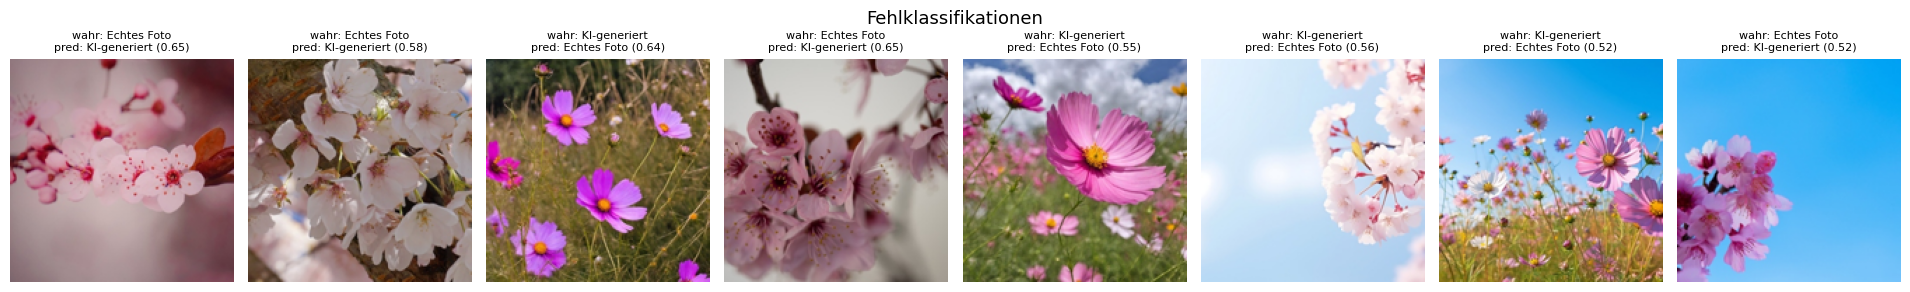

In [21]:
wrong = np.where(val_preds != val_targets)[0]
print(f"Falsch klassifiziert: {len(wrong)} von {len(val_targets)} Validierungsbildern")

if len(wrong) > 0:
    n = min(8, len(wrong))
    fig, axes = plt.subplots(1, n, figsize=(2.4 * n, 3.0))
    if n == 1:
        axes = [axes]
    for ax, w in zip(axes, wrong[:n]):
        fname = train_df.iloc[val_idx[w]]["Image"]
        with Image.open(TRAIN_DIR / fname) as im:
            ax.imshow(im.convert("RGB").resize((160, 160)))
        conf = val_probs[w].max()
        ax.set_title(f"wahr: {CLASS_NAMES[val_targets[w]]}\n"
                     f"pred: {CLASS_NAMES[val_preds[w]]} ({conf:.2f})", fontsize=8)
        ax.axis("off")
    fig.suptitle("Fehlklassifikationen", fontsize=13)
    plt.tight_layout(); plt.show()

## D.3 Wie sicher ist sich das Modell?

Ein gut kalibriertes Modell ist bei korrekten Vorhersagen sicher und bei Fehlern unsicher.
Viele Fehler mit hoher Konfidenz sind ein Warnsignal (typisch bei Overfitting).

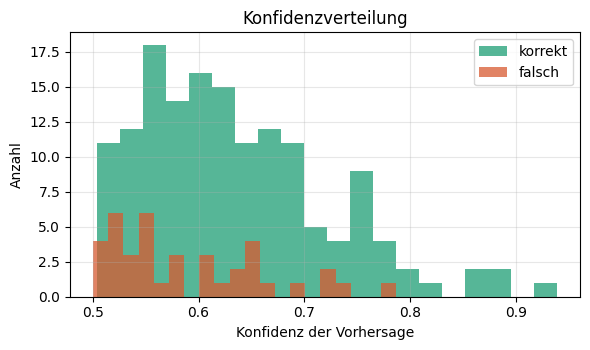

Mittlere Konfidenz bei korrekten Vorhersagen: 0.634
Mittlere Konfidenz bei Fehlern              : 0.589


In [22]:
conf = val_probs.max(axis=1)
correct_mask = (val_preds == val_targets)

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.hist(conf[correct_mask],  bins=20, alpha=.75, label="korrekt",  color="#1D9E75")
ax.hist(conf[~correct_mask], bins=20, alpha=.75, label="falsch",   color="#D85A30")
ax.set_xlabel("Konfidenz der Vorhersage"); ax.set_ylabel("Anzahl")
ax.set_title("Konfidenzverteilung"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

print(f"Mittlere Konfidenz bei korrekten Vorhersagen: {conf[correct_mask].mean():.3f}")
if (~correct_mask).any():
    print(f"Mittlere Konfidenz bei Fehlern              : {conf[~correct_mask].mean():.3f}")

## D.4 Tatsächlich gemessene Ergebnisse (CPU-Testlauf)

Beide Konfigurationen wurden auf den echten Daten trainiert (CPU, identischer Seed und Split):

| | A: konservative Augmentation | B: blumenspezifische Augmentation |
|:---|---:|---:|
| Epochen | 10 (abgebrochen) | 20 (vollständig) |
| **Beste Val-Accuracy** | **0,746** | **0,783** |
| Train-Accuracy final | 1,000 | 1,000 |
| Gap Train − Val | 0,265 | 0,296 |
| Train-Acc = 100 % ab Epoche | 7 | 6 |

**Ehrliche Einordnung — drei Dinge, die man daraus nicht schliessen darf:**

1. **Der Unterschied 0,746 → 0,783 ist statistisch nicht belastbar.** Das Validierungsset hat nur
   **189 Bilder**; ein einzelnes Bild entspricht 0,53 %. Die Differenz sind ganze **7 Bilder** — das liegt
   im Rauschen eines einzelnen Splits.
2. **Die stärkere Augmentation hat das Overfitting nicht gelöst.** Beide Läufe erreichen 100 % Train-Accuracy.
   Das Modell hat für 756 Bilder schlicht zu viel Kapazität.
3. **Die Val-Accuracy schwankt zwischen Epochen um ±5 Punkte** (0,68 bis 0,78). Auf so einem Signal darf man
   keine Hyperparameter tunen.

**Konsequenz:** Der nächste sinnvolle Schritt ist nicht "noch mehr Augmentation", sondern
**k-Fold Cross-Validation** (Teil F, Punkt 1) — sonst optimierst du auf Rauschen. Ein realistischer
Erwartungswert für ein From-Scratch-CNN auf diesem Datensatz liegt bei **70–80 %**.

---
# Teil E — Kaggle-Submission

Jetzt wenden wir das beste Modell auf die 402 Testbilder an und schreiben die Datei im Format der
`sample_submission.csv` (Spalten `Image` und `Label`).

In [23]:
test_ds = RealOrAIDataset(test_df, TEST_DIR, transform=eval_transform, has_labels=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

model.eval()
pred_labels, pred_files = [], []

with torch.no_grad():
    for data, fnames in test_loader:
        data   = data.to(device)
        logits = model(data)
        preds  = logits.argmax(dim=1).cpu().numpy()
        pred_labels.extend(preds.tolist())
        pred_files.extend(list(fnames))

submission = pd.DataFrame({"Image": pred_files, "Label": pred_labels})

# Reihenfolge an die sample_submission angleichen (sicherer fuer Kaggle)
submission = (submission.set_index("Image")
                        .loc[sample_df["Image"]]
                        .reset_index())

submission.to_csv("submission.csv", index=False)

print("submission.csv geschrieben:", submission.shape)
print("\nVerteilung der Vorhersagen:")
for lab, n in submission["Label"].value_counts().sort_index().items():
    print(f"  Label {lab} ({CLASS_NAMES[lab]:12s}): {n:3d}  ({n / len(submission):.1%})")
display(submission.head())

submission.csv geschrieben: (402, 2)

Verteilung der Vorhersagen:
  Label 0 (KI-generiert): 224  (55.7%)
  Label 1 (Echtes Foto ): 178  (44.3%)


,Image,Label
0,946.jpg,1
1,947.jpg,1
2,948.jpg,0
3,949.jpg,1
4,950.jpg,0


**Plausibilitäts-Check:** Die Verteilung sollte ungefähr 50/50 zwischen "KI-generiert" und "Echtes Foto"
liegen, da auch das Trainingsset balanciert ist. Sagt das Modell fast nur eine Klasse vorher, stimmt etwas
nicht — dann zuerst Lernkurven und Konfusionsmatrix prüfen.

⚠️ **Vor dem Upload prüfen:** Die Spalten müssen exakt `Image` und `Label` heißen und die Labels müssen
`0`/`1` sein (nicht die Klartextnamen) — Kaggle erwartet dasselbe Format wie `sample_submission.csv`.

---
# Teil F — Nächste Schritte (nach den Messergebnissen priorisiert)

1. **k-Fold Cross-Validation (5 Folds) — zuerst!** Bei 189 Validierungsbildern ist ein einzelner Split zu
   verrauscht, um Konfigurationen zu vergleichen (siehe D.4). Erst mit CV weisst du, ob eine Änderung wirkt.
   Nebeneffekt: Die 5 Modelle lassen sich zu einem Ensemble mitteln.
2. **Modellkapazität reduzieren.** Beide Läufe erreichen 100 % Train-Accuracy — das Netz ist für 756 Bilder
   zu gross. Probiere die Kanäle zu halbieren (16/32/64/128) oder einen Block zu entfernen.
3. **Auflösung erhöhen** (`IMG_SIZE = 192` oder `256`, der Cache liegt bereits bei 256 px). KI-Artefakte in
   Blütentexturen sind hochfrequent und gehen beim Skalieren auf 128 px teilweise verloren.
4. **Test-Time Augmentation:** dasselbe Testbild in mehreren Rotationen/Crops vorhersagen und mitteln.
   Bei Blumen besonders naheliegend, da rotationsinvariant.
5. **Early Stopping mit Patience** statt fester Epochenzahl.

> ⚠️ **Zur Erwartungshaltung:** Ein From-Scratch-CNN ist auf 945 Bildern strukturell limitiert. Der mit
> Abstand grösste Sprung käme von **Transfer Learning** (vortrainiertes ResNet, wie in Assignment 3) — das
> hast du für dieses Projekt aber bewusst ausgeschlossen. Falls die Vorgabe das doch erlaubt, wäre das der
> effektivste einzelne Hebel.

> 📌 **Für den Projektbericht:** Dokumentiere jedes Experiment als Zeile (Änderung → Val-Accuracy über alle
> Folds, mit Standardabweichung). Genau diese Systematik ist meist notenrelevant.